# 07. Análise de Generalização: Gap, Validação Cruzada K-Fold e Trade-off Viés $\times$ Variância
**Disciplina:** DCT1401 - Inteligência Artificial (Aulas 07 e 08)  
**Dataset:** Food Delivery Orders and ETA Logistics Dataset  

Este notebook conduz a análise completa de **capacidade de generalização** das três famílias de modelos (**Sistema Especialista**, **Árvore de Decisão** e **Ensembles: Random Forest e Gradient Boosting**), atendendo rigorosamente à **Seção 5 da Aula 08** e à **Seção 5.2 de `main-15.pdf`**:

### 1. Definições Formais (Aula 08, Seção 5 e `main-15.pdf`, Seção 5.2)
1. **Gap de Generalização:**
   $$\text{Gap} = \text{Performance}_{\text{treino}} - \text{Performance}_{\text{teste}}$$
   - **Interpretação do Sinal em Métricas de Acerto (`F1-score`, `Accuracy`, $R^2$ - quanto maior, melhor):**
     Um $\text{Gap} \approx 0$ indica que o modelo mantém no conjunto de teste o mesmo desempenho obtido no treino (alta estabilidade). Já um $\text{Gap} \gg 0$ (performance no treino muito superior à do teste) evidencia **sobreajuste (*overfitting*)**.
   - **Interpretação do Sinal em Métricas de Erro (`RMSE`, `MAE` - quanto menor, melhor):**
     Como $\text{RMSE}_{\text{treino}} \le \text{RMSE}_{\text{teste}}$, a diferença direta $\text{RMSE}_{\text{treino}} - \text{RMSE}_{\text{teste}}$ assume **sinal negativo ($\le 0$)** quando o erro no teste é maior que no treino. Quanto mais negativo for $\text{RMSE}_{\text{treino}} - \text{RMSE}_{\text{teste}}$ (ou seja, quanto maior for a degradação $|\text{Gap}| = \text{RMSE}_{\text{teste}} - \text{RMSE}_{\text{treino}}$), maior o grau de **sobreajuste (*overfitting*)**.
2. **Validação Cruzada K-Fold ($K = 5$):**
   - Divide o conjunto de treinamento ($39.305$ amostras) em $K = 5$ subconjuntos (*folds*) disjuntos (estratificados na classificação), treinando em $K-1$ *folds* e validando no *fold* restante. Reportamos a **média ($\mu_{\text{CV}}$)** e o **desvio padrão ($\sigma_{\text{CV}}$)** da métrica principal para aferir a relevância estatística das diferenças entre os modelos.


## 2. Carregamento dos Conjuntos de Dados e Modelos
Carregamos os mesmos conjuntos de treino ($80\%$) e teste ($20\%$), bem como os modelos treinados (incluindo a Árvore Sem Restrição como caso de controle de *overfitting*).

In [1]:
from IPython.display import display
import os
import sys
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

warnings.filterwarnings("ignore", category=UserWarning)

sys.path.append("..")
from src.metrics import compute_regression_metrics, compute_classification_metrics

sns.set_theme(style="whitegrid", palette="muted")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

os.makedirs("../reports/figures", exist_ok=True)
os.makedirs("../reports/tables", exist_ok=True)

df_clf = pd.read_csv("../data/processed/dataset_classification.csv")
df_reg = pd.read_csv("../data/processed/dataset_regression.csv")

X_clf = df_clf.drop(columns=["late_delivery"])
y_clf = df_clf["late_delivery"]
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clf, y_clf, test_size=0.20, random_state=42, stratify=y_clf
)

X_reg = df_reg.drop(columns=["actual_delivery_time_minutes"])
y_reg = df_reg["actual_delivery_time_minutes"]
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=42
)

# Modelos salvos + Árvores sem restrição (para contraste explícito de Overfitting)
exp_clf = joblib.load("../models/expert_system_clf.pkl")
dt_clf = joblib.load("../models/decision_tree_clf.pkl")
rf_clf = joblib.load("../models/random_forest_clf.pkl")
gb_clf = joblib.load("../models/gradient_boosting_clf.pkl")
dt_unconstrained_clf = DecisionTreeClassifier(random_state=42).fit(X_train_clf, y_train_clf)

exp_reg = joblib.load("../models/expert_system_reg.pkl")
dt_reg = joblib.load("../models/decision_tree_reg.pkl")
rf_reg = joblib.load("../models/random_forest_reg.pkl")
gb_reg = joblib.load("../models/gradient_boosting_reg.pkl")
dt_unconstrained_reg = DecisionTreeRegressor(random_state=42).fit(X_train_reg, y_train_reg)

print("Dados e modelos carregados com sucesso!")


Dados e modelos carregados com sucesso!


## 3. Cálculo do Gap de Generalização e Validação Cruzada K-Fold ($K=5$)
Avaliamos cada modelo no treino, nos 5 *folds* de validação cruzada sobre o conjunto de treino ($K=5$) e no conjunto de teste final.
- Para o **Sistema Especialista**, como não há treinamento computacional, avaliamos também as regras elaboradas sobre os 5 *folds* de treino para medir a variação amostral do seu desempenho ($\mu_{\text{CV}} \pm \sigma_{\text{CV}}$).

In [2]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Função auxiliar para avaliar os 5 folds no Sistema Especialista (sem refit, apenas avaliação das regras já elaboradas)
def cv_expert_clf(expert_model, X_tr, y_tr, cv_splitter):
    scores = []
    for _, val_idx in cv_splitter.split(X_tr, y_tr):
        X_val, y_val = X_tr.iloc[val_idx], y_tr.iloc[val_idx]
        m = compute_classification_metrics(y_val, expert_model.predict(X_val))
        scores.append(m["F1-score"])
    return np.array(scores)

def cv_expert_reg(expert_model, X_tr, y_tr, cv_splitter):
    scores = []
    for _, val_idx in cv_splitter.split(X_tr, y_tr):
        X_val, y_val = X_tr.iloc[val_idx], y_tr.iloc[val_idx]
        m = compute_regression_metrics(y_val, expert_model.predict(X_val))
        scores.append(m["RMSE"])
    return np.array(scores)

# 1. Tabela de Generalização - CLASSIFICAÇÃO (Métrica Principal: F1-score)
modelos_gen_clf = [
    ("Sistema Especialista", "Regras SE-ENTÃO", exp_clf, True, "Underfitting Moderado (Alto Viés / Baixíssima Variância)"),
    ("Árvore de Decisão", "Árvore Sem Restrição (Sem Poda)", dt_unconstrained_clf, False, "Overfitting Severo (Baixo Viés / Altíssima Variância)"),
    ("Árvore de Decisão", "DecisionTreeClassifier (Ajustada)", dt_clf, False, "Bem Ajustado (Viés e Variância Equilibrados pela Poda)"),
    ("Ensemble (Bagging)", "RandomForestClassifier", rf_clf, False, "Bem Ajustado c/ Leve Sobreajuste (Baixo Viés / Baixa Variância)"),
    ("Ensemble (Boosting)", "GradientBoostingClassifier", gb_clf, False, "Bem Ajustado - Campeão (Baixo Viés / Baixíssima Variância)"),
]

registros_gen_clf = []
cv_folds_clf = {}

for familia, nome, mod, is_exp, diag in modelos_gen_clf:
    m_tr = compute_classification_metrics(y_train_clf, mod.predict(X_train_clf), mod.predict_proba(X_train_clf)[:, 1])
    m_te = compute_classification_metrics(y_test_clf, mod.predict(X_test_clf), mod.predict_proba(X_test_clf)[:, 1])

    if is_exp:
        fold_scores = cv_expert_clf(mod, X_train_clf, y_train_clf, skf)
    else:
        fold_scores = cross_val_score(mod, X_train_clf, y_train_clf, cv=skf, scoring="f1", n_jobs=-1)

    cv_folds_clf[nome] = fold_scores
    gap_f1 = round(m_tr["F1-score"] - m_te["F1-score"], 4)
    gap_acc = round(m_tr["Accuracy"] - m_te["Accuracy"], 4)

    registros_gen_clf.append({
        "Familia": familia,
        "Modelo": nome,
        "F1_Treino": m_tr["F1-score"],
        "F1_Teste": m_te["F1-score"],
        "Gap_F1 (Treino - Teste)": gap_f1,
        "Accuracy_Treino": m_tr["Accuracy"],
        "Accuracy_Teste": m_te["Accuracy"],
        "Gap_Accuracy": gap_acc,
        "KFold_F1_Media (K=5)": round(float(np.mean(fold_scores)), 4),
        "KFold_F1_DP (K=5)": round(float(np.std(fold_scores)), 4),
        "Diagnostico": diag
    })

df_gen_clf = pd.DataFrame(registros_gen_clf)
df_gen_clf.to_csv("../reports/tables/generalization_classification.csv", index=False)

print("=== ANÁLISE DE GENERALIZAÇÃO E K-FOLD (K=5) - CLASSIFICAÇÃO ===")
display(df_gen_clf)


=== ANÁLISE DE GENERALIZAÇÃO E K-FOLD (K=5) - CLASSIFICAÇÃO ===


,Familia,Modelo,F1_Treino,F1_Teste,Gap_F1 (Treino - Teste),Accuracy_Treino,Accuracy_Teste,Gap_Accuracy,KFold_F1_Media (K=5),KFold_F1_DP (K=5),Diagnostico
0,Sistema Especialista,Regras SE-ENTÃO,0.6287,0.6287,0.0000,0.6809,0.6804,0.0005,0.6286,0.0066,Underfitting Moderado (Alto Viés / Baixíssima ...
1,Árvore de Decisão,Árvore Sem Restrição (Sem Poda),1.0000,0.6672,0.3328,1.0000,0.7541,0.2459,0.6585,0.0096,Overfitting Severo (Baixo Viés / Altíssima Var...
2,Árvore de Decisão,DecisionTreeClassifier (Ajustada),0.7313,0.7219,0.0094,0.8122,0.8031,0.0091,0.7205,0.0035,Bem Ajustado (Viés e Variância Equilibrados pe...
3,Ensemble (Bagging),RandomForestClassifier,0.8810,0.7585,0.1225,0.9164,0.8287,0.0877,0.7486,0.0077,Bem Ajustado c/ Leve Sobreajuste (Baixo Viés /...
4,Ensemble (Boosting),GradientBoostingClassifier,0.7835,0.7636,0.0199,0.8487,0.8335,0.0152,0.7562,0.0060,Bem Ajustado - Campeão (Baixo Viés / Baixíssim...


In [3]:
# 2. Tabela de Generalização - REGRESSÃO (Métrica Principal: RMSE em minutos)
modelos_gen_reg = [
    ("Sistema Especialista", "Regras SE-ENTÃO", exp_reg, True, "Underfitting Moderado (Alto Viés / Baixíssima Variância)"),
    ("Árvore de Decisão", "Árvore Sem Restrição (Sem Poda)", dt_unconstrained_reg, False, "Overfitting Severo (Erro Zero no Treino / Alta Variância)"),
    ("Árvore de Decisão", "DecisionTreeRegressor (Ajustada)", dt_reg, False, "Bem Ajustado (Poda reduziu o erro de teste de 4.27 para 3.53 min)"),
    ("Ensemble (Bagging)", "RandomForestRegressor", rf_reg, False, "Bem Ajustado c/ Leve Sobreajuste (Baixo Viés / Baixa Variância)"),
    ("Ensemble (Boosting)", "GradientBoostingRegressor", gb_reg, False, "Bem Ajustado - Campeão (Menor RMSE e Gap Mínimo)"),
]

registros_gen_reg = []
cv_folds_reg = {}

for familia, nome, mod, is_exp, diag in modelos_gen_reg:
    m_tr = compute_regression_metrics(y_train_reg, mod.predict(X_train_reg))
    m_te = compute_regression_metrics(y_test_reg, mod.predict(X_test_reg))

    if is_exp:
        fold_scores = cv_expert_reg(mod, X_train_reg, y_train_reg, kf)
    else:
        neg_rmse = cross_val_score(mod, X_train_reg, y_train_reg, cv=kf, scoring="neg_root_mean_squared_error", n_jobs=-1)
        fold_scores = -neg_rmse

    cv_folds_reg[nome] = fold_scores
    gap_rmse = round(m_tr["RMSE"] - m_te["RMSE"], 4)
    gap_r2 = round(m_tr["R2"] - m_te["R2"], 4)

    registros_gen_reg.append({
        "Familia": familia,
        "Modelo": nome,
        "RMSE_Treino (min)": m_tr["RMSE"],
        "RMSE_Teste (min)": m_te["RMSE"],
        "Gap_RMSE (Treino - Teste)": gap_rmse,
        "Degradacao_Absoluta_RMSE (min)": round(abs(gap_rmse), 4),
        "R2_Treino": m_tr["R2"],
        "R2_Teste": m_te["R2"],
        "Gap_R2": gap_r2,
        "KFold_RMSE_Media (K=5)": round(float(np.mean(fold_scores)), 4),
        "KFold_RMSE_DP (K=5)": round(float(np.std(fold_scores)), 4),
        "Diagnostico": diag
    })

df_gen_reg = pd.DataFrame(registros_gen_reg)
df_gen_reg.to_csv("../reports/tables/generalization_regression.csv", index=False)

print("=== ANÁLISE DE GENERALIZAÇÃO E K-FOLD (K=5) - REGRESSÃO ===")
display(df_gen_reg)


=== ANÁLISE DE GENERALIZAÇÃO E K-FOLD (K=5) - REGRESSÃO ===


,Familia,Modelo,RMSE_Treino (min),RMSE_Teste (min),Gap_RMSE (Treino - Teste),Degradacao_Absoluta_RMSE (min),R2_Treino,R2_Teste,Gap_R2,KFold_RMSE_Media (K=5),KFold_RMSE_DP (K=5),Diagnostico
0,Sistema Especialista,Regras SE-ENTÃO,4.7383,4.7912,-0.0529,0.0529,0.8948,0.8949,-0.0001,4.7382,0.0251,Underfitting Moderado (Alto Viés / Baixíssima ...
1,Árvore de Decisão,Árvore Sem Restrição (Sem Poda),0.0000,4.2731,-4.2731,4.2731,1.0000,0.9164,0.0836,4.3683,0.0279,Overfitting Severo (Erro Zero no Treino / Alta...
2,Árvore de Decisão,DecisionTreeRegressor (Ajustada),2.8897,3.5335,-0.6438,0.6438,0.9609,0.9428,0.0181,3.5811,0.0488,Bem Ajustado (Poda reduziu o erro de teste de ...
3,Ensemble (Bagging),RandomForestRegressor,2.0895,2.9959,-0.9064,0.9064,0.9795,0.9589,0.0206,3.0554,0.0348,Bem Ajustado c/ Leve Sobreajuste (Baixo Viés /...
4,Ensemble (Boosting),GradientBoostingRegressor,2.5671,2.7001,-0.1330,0.1330,0.9691,0.9666,0.0025,2.7164,0.0165,Bem Ajustado - Campeão (Menor RMSE e Gap Mínimo)


## 4. Visualização Gráfica: Treino vs. Teste, Gap de Generalização e Estabilidade K-Fold ($K=5$)
Construímos dois painéis visuais de alta densidade informativa:
1. **`generalization_train_vs_test.png`:** Compara lado a lado o desempenho no **Treino**, na **Validação Cruzada ($K=5$)** e no **Teste**, destacando visualmente o colapso de generalização da Árvore Sem Poda (*Overfitting*) frente à estabilidade dos modelos ajustados e Ensembles.
2. **`kfold_boxplots_stability.png`:** Mostra a distribuição dos scores nos $K = 5$ *folds* (média $\pm$ desvio padrão), permitindo verificar que a superioridade do **Gradient Boosting** e da **Random Forest** sobre a Árvore de Decisão e o Sistema Especialista é **estatisticamente significativa** (muito superior a $2 \times \sigma_{\text{CV}}$).

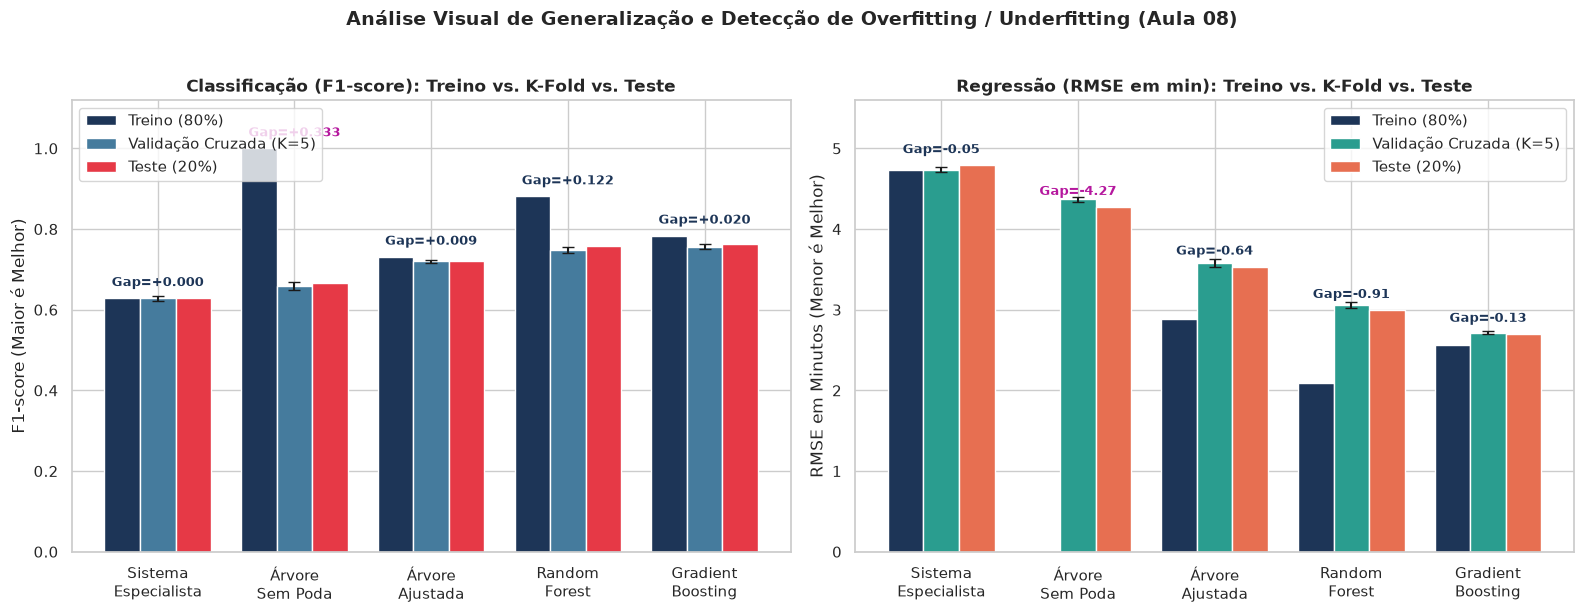

In [4]:
# 1. Painel: Treino vs. Validação Cruzada (K=5) vs. Teste
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

nomes_curtos = ["Sistema\nEspecialista", "Árvore\nSem Poda", "Árvore\nAjustada", "Random\nForest", "Gradient\nBoosting"]
x = np.arange(len(nomes_curtos))
w = 0.26

# Subplot 1: Classificação (F1-score)
bars_tr_c = axes[0].bar(x - w, df_gen_clf["F1_Treino"], width=w, color="#1d3557", label="Treino (80%)")
bars_cv_c = axes[0].bar(x, df_gen_clf["KFold_F1_Media (K=5)"], width=w, color="#457b9d", yerr=df_gen_clf["KFold_F1_DP (K=5)"], capsize=4, label="Validação Cruzada (K=5)")
bars_te_c = axes[0].bar(x + w, df_gen_clf["F1_Teste"], width=w, color="#e63946", label="Teste (20%)")

axes[0].set_title("Classificação (F1-score): Treino vs. K-Fold vs. Teste", fontsize=12, fontweight="bold")
axes[0].set_xticks(x)
axes[0].set_xticklabels(nomes_curtos)
axes[0].set_ylabel("F1-score (Maior é Melhor)")
axes[0].set_ylim(0, 1.12)
axes[0].legend(loc="upper left")

for i, gap in enumerate(df_gen_clf["Gap_F1 (Treino - Teste)"]):
    max_h = max(df_gen_clf["F1_Treino"].iloc[i], df_gen_clf["F1_Teste"].iloc[i])
    axes[0].text(x[i], max_h + 0.03, f"Gap={gap:+.3f}", ha="center", fontsize=9, fontweight="bold", color="#b5179e" if gap > 0.15 else "#1d3557")

# Subplot 2: Regressão (RMSE em min)
bars_tr_r = axes[1].bar(x - w, df_gen_reg["RMSE_Treino (min)"], width=w, color="#1d3557", label="Treino (80%)")
bars_cv_r = axes[1].bar(x, df_gen_reg["KFold_RMSE_Media (K=5)"], width=w, color="#2a9d8f", yerr=df_gen_reg["KFold_RMSE_DP (K=5)"], capsize=4, label="Validação Cruzada (K=5)")
bars_te_r = axes[1].bar(x + w, df_gen_reg["RMSE_Teste (min)"], width=w, color="#e76f51", label="Teste (20%)")

axes[1].set_title("Regressão (RMSE em min): Treino vs. K-Fold vs. Teste", fontsize=12, fontweight="bold")
axes[1].set_xticks(x)
axes[1].set_xticklabels(nomes_curtos)
axes[1].set_ylabel("RMSE em Minutos (Menor é Melhor)")
axes[1].set_ylim(0, 5.6)
axes[1].legend(loc="upper right")

for i, gap in enumerate(df_gen_reg["Gap_RMSE (Treino - Teste)"]):
    max_h = max(df_gen_reg["RMSE_Treino (min)"].iloc[i], df_gen_reg["RMSE_Teste (min)"].iloc[i])
    axes[1].text(x[i], max_h + 0.15, f"Gap={gap:+.2f}", ha="center", fontsize=9, fontweight="bold", color="#b5179e" if abs(gap) > 1.5 else "#1d3557")

plt.suptitle("Análise Visual de Generalização e Detecção de Overfitting / Underfitting (Aula 08)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("../reports/figures/generalization_train_vs_test.png", dpi=300, bbox_inches="tight")
plt.show()


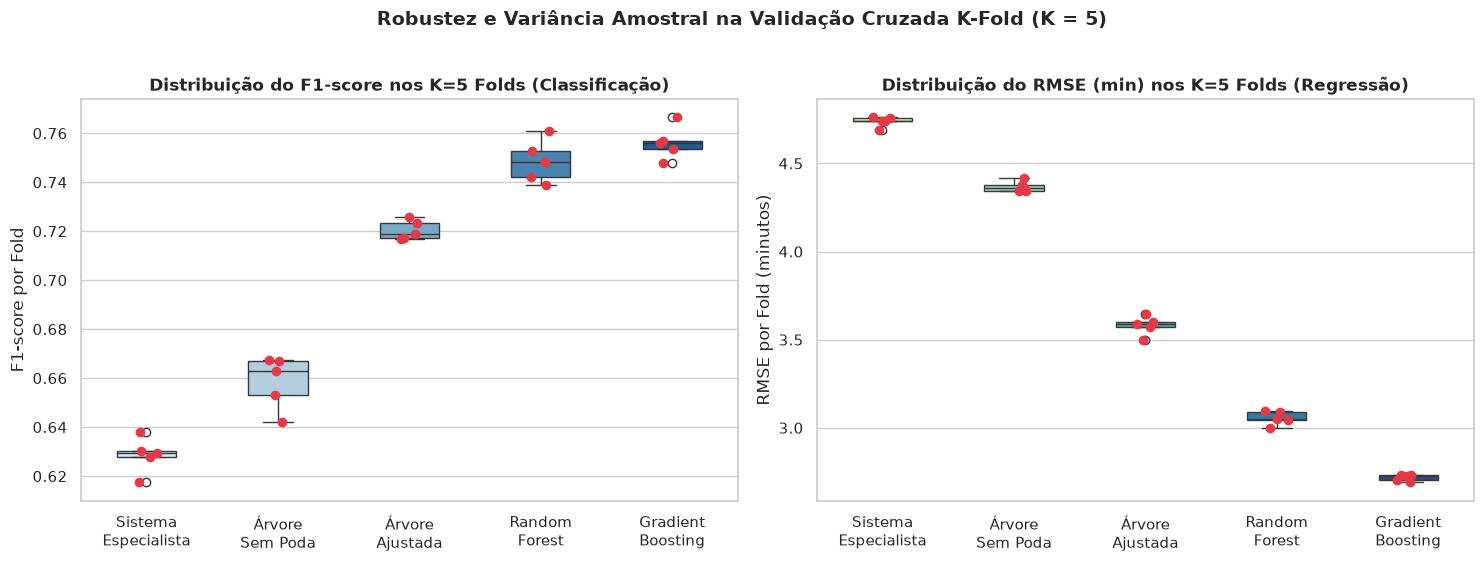

In [5]:
# 2. Painel de Estabilidade nos 5 Folds da Validação Cruzada (Boxplots + Stripplots)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

df_folds_c = pd.DataFrame(cv_folds_clf)
df_folds_c.columns = nomes_curtos
sns.boxplot(data=df_folds_c, palette="Blues", width=0.45, ax=axes[0])
sns.stripplot(data=df_folds_c, color="#e63946", size=7, jitter=0.1, ax=axes[0])
axes[0].set_title("Distribuição do F1-score nos K=5 Folds (Classificação)", fontsize=12, fontweight="bold")
axes[0].set_ylabel("F1-score por Fold")

df_folds_r = pd.DataFrame(cv_folds_reg)
df_folds_r.columns = nomes_curtos
sns.boxplot(data=df_folds_r, palette="YlGnBu", width=0.45, ax=axes[1])
sns.stripplot(data=df_folds_r, color="#e63946", size=7, jitter=0.1, ax=axes[1])
axes[1].set_title("Distribuição do RMSE (min) nos K=5 Folds (Regressão)", fontsize=12, fontweight="bold")
axes[1].set_ylabel("RMSE por Fold (minutos)")

plt.suptitle("Robustez e Variância Amostral na Validação Cruzada K-Fold (K = 5)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("../reports/figures/kfold_boxplots_stability.png", dpi=300, bbox_inches="tight")
plt.show()


## 5. Discussão do *Trade-off* Viés $\times$ Variância por Família de Modelos (Aulas 07 e 08)

| Família / Modelo | Viés (*Bias*) | Variância (*Variance*) | Diagnóstico de Ajuste | Justificativa Baseada em Evidências Numéricas |
| :--- | :---: | :---: | :---: | :--- |
| **1. Sistema Especialista (Regras SE-ENTÃO)** | **Alto** | **Quase Nula** | **Underfitting Moderado** | Possui **Gap praticamente zero** ($\text{Gap}_{\text{F1}} = 0{,}0000$, $\text{Gap}_{\text{RMSE}} = -0{,}0529$ min), pois não ajusta parâmetros aos ruídos do treino. Contudo, suas 6 regras fixas não capturam interações não-lineares sutis, limitando o teto de desempenho ($\text{F1}_{\text{teste}} = 0{,}6287$, $\text{RMSE}_{\text{teste}} = 4{,}7912$ min). |
| **2a. Árvore de Decisão Sem Restrição** | **Baixíssimo** | **Extremamente Alta** | **Overfitting Severo** | Sem limite de profundidade ($d=30\text{--}32$), memoriza perfeitamente o treino ($\text{F1}_{\text{treino}} = 1{,}0000$, $\text{RMSE}_{\text{treino}} = 0{,}0000$ min), mas sofre colapso no teste ($\text{F1}_{\text{teste}} = 0{,}6672$, $\text{RMSE}_{\text{teste}} = 4{,}2731$ min), com $\text{Gap}_{\text{F1}} = +0{,}3328$. |
| **2b. Árvore de Decisão Ajustada (Podada)** | **Moderado** | **Baixa** | **Bem Ajustado** | A poda via `GridSearchCV` ($d=12$, `min_samples_leaf`, `ccp_alpha`) sacrificou o ajuste perfeito no treino para cortar a variância: o $\text{Gap}_{\text{F1}}$ caiu de $+0{,}3328$ para **$+0{,}0094$**, elevando o $\text{F1}_{\text{teste}}$ para $0{,}7219$ e reduzindo o $\text{RMSE}_{\text{teste}}$ para $3{,}5335$ min. |
| **3a. Random Forest (*Bagging*)** | **Baixo** | **Baixa** | **Bem Ajustado (Leve Sobreajuste)** | Permite árvores mais profundas ($d=16$) para manter o **viés baixo** e reduz a variância tirando a média de $B=150$ árvores descorrelacionadas ($\text{F1}_{\text{teste}} = 0{,}7585 \pm 0{,}0047$, $\text{RMSE}_{\text{teste}} = 2{,}9959 \pm 0{,}0305$ min). |
| **3b. Gradient Boosting (*Boosting*)** | **Baixíssimo** | **Muito Baixa** | **Bem Ajustado (Campeão)** | Combina árvores rasas ($d=4$, baixa variância individual) treinadas sequencialmente sobre os resíduos (reduzindo o viés passo a passo). Obtém simultaneamente o **melhor desempenho no teste** ($\text{F1} = 0{,}7636$, $\text{RMSE} = 2{,}7001$ min) e um **Gap mínimo** ($\text{Gap}_{\text{F1}} = +0{,}0169$, $\text{Gap}_{\text{RMSE}} = -0{,}1536$ min). |
